# 해외ETF마스터(PREF02N001) EDA

**데이터셋**: `PREF02N001_해외ETF마스터`
**최종 추출일자(스키마 기준)**: 2026-07-11
**목적**: 해외 상장 ETF/ETN 마스터 데이터의 구조, 결측/이상치, 범주형·수치형 분포, 지수추종·레버리지·통화 특성을 탐색

**국내ETF마스터와의 스키마 차이(중요)**:
- PK 표기가 `pd_itm_no` **단 하나**뿐입니다(국내ETF마스터는 `pd_exg_mkt_cd`/`pd_itm_no`/`pd_itm_no_ma` 3중 표기였음).
- 수익률 컬럼이 `du_er_1d` **1일 수익률 하나뿐**입니다(국내ETF마스터는 1D/1M/3M/6M/1Y/YTD 6종) — "기간이 길수록 결측 증가" 패턴 비교가 불가능하므로 이번 노트북에는 해당 섹션이 없습니다.
- 추적오차율(du_chas_errt) 컬럼이 없고, 대신 `cu_index_tracking_yn`(지수추종 여부 플래그)와 `du_diff_rt`(괴리율)만 존재합니다.
- `cu_etn_yn`(ETN 여부), `cu_inverse_short_yn`(인버스/공매도 여부), `cu_index_repl_mthd`(지수복제방식)처럼 국내ETF마스터에는 없던 **명시적 상품 속성 플래그**가 추가되어 있습니다 — 국내ETF마스터에서는 이런 속성을 이름 패턴이나 배수 컬럼으로 추정해야 했던 것과 대조적입니다.
- `pd_isin_cd`(ISIN), `pd_lipper_id`(Lipper ID), `pd_us_cik`(미국 SEC CIK 번호), `pd_trd_ccy`(거래통화, `pd_curr_cd`와 별도) 등 **해외 상장/글로벌 데이터 벤더 연계용 식별자**가 새로 존재합니다 — 시장별로 존재 여부가 다를 것으로 예상되어 완결성(completeness)을 별도로 확인합니다.
- 스키마 파일에 컬럼한글명·값 예시가 채워져 있지 않아, 컬럼 의미는 컬럼명과 접두사 규칙(국내ETF마스터와 동일: `pd_`/`cu_`/`du_`/`wu_`/`ru_`)으로 추정했습니다. 실제 데이터를 보고 의미가 다르면 알려주세요.


## 1. 라이브러리 임포트 및 환경 설정

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

%matplotlib inline


In [2]:
# --- 차트 스타일 (색상 시스템: 고정 순서 카테고리 팔레트) -------------------
# 국내채권마스터/국내ETF마스터/공모펀드마스터 EDA 노트북과 동일한 팔레트를 재사용해 시각적 일관성을 유지합니다.
CAT_COLORS = [
    "#2a78d6",  # 1 blue
    "#eb6834",  # 2 orange
    "#1baf7a",  # 3 aqua
    "#eda100",  # 4 yellow
    "#e87ba4",  # 5 magenta
    "#008300",  # 6 green
    "#4a3aa7",  # 7 violet
    "#e34948",  # 8 red
]
SEQ_BLUE = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
SEQ_BLUE_CMAP = sns.blend_palette(SEQ_BLUE, as_cmap=True)
DIVERGING_CMAP = sns.diverging_palette(220, 10, s=75, l=50, sep=10, as_cmap=True)  # blue-gray-red

INK_PRIMARY = "#0b0b0b"
INK_SECONDARY = "#52514e"
INK_MUTED = "#898781"
GRIDLINE = "#e1e0d9"
SURFACE = "#fcfcfb"

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": INK_SECONDARY,
    "axes.titlecolor": INK_PRIMARY,
    "text.color": INK_PRIMARY,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "grid.color": GRIDLINE,
    "grid.linewidth": 0.6,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
    "figure.dpi": 110,
})


def cat_colors(n: int) -> list:
    '''카테고리 개수만큼 고정 순서 팔레트에서 색을 가져온다. 8개 초과 시 순환 사용.'''
    if n <= len(CAT_COLORS):
        return CAT_COLORS[:n]
    reps = (n // len(CAT_COLORS)) + 1
    return (CAT_COLORS * reps)[:n]


## 2. 데이터 로드

`DATA_PATH`만 실제 파일 경로로 바꿔서 사용하세요. csv / parquet / xlsx 로더를 모두 준비해뒀고,
`DATA_PATH`의 확장자에 따라 자동으로 분기합니다.


In [3]:
# TODO: 실제 데이터 경로로 수정 (동료 전처리본 v4 기준 경로를 기본값으로 넣어둠)

DATA_PATH = Path("../perprocessed_datas/v4/PREF02N001_해외ETF마스터_20260711_datarows.xlsx")

# 스키마 기준 컬럼 순서 (raw 데이터 컬럼명이 다르면 여기만 맞춰서 조정)
SCHEMA_COLUMNS = [
    "cu_base_index", "cu_charge_rt", "cu_etn_yn", "cu_fund_mgmt_co", "cu_index_repl_mthd",
    "cu_index_tracking_yn", "cu_inverse_short_yn", "cu_lev_fector", "cu_strtegy", "cu_upt_dt",
    "du_base_dt_match_yn", "du_bpr", "du_clpr", "du_clpr_base_dt", "du_clpr_src",
    "du_diff_rt", "du_er_1d", "du_hpr", "du_last_aum", "du_last_nav",
    "du_lpr", "du_nav_base_dt", "du_opr", "du_upt_dt", "du_val_1d", "du_vol_1d",
    "pd_abrv_nm", "pd_curr_cd", "pd_exg_mkt_cd", "pd_grp_no", "pd_isin_cd",
    "pd_itm_no", "pd_itm_no_ma", "pd_lipper_id", "pd_lstg_dt", "pd_lst_price",
    "pd_lst_stk_cnt", "pd_mkt_id", "pd_nm", "pd_sale_yn", "pd_trd_ccy",
    "pd_tr_yn", "pd_us_cik", "ru_mkt_price", "ru_mkt_volume",
    "wu_core_yn", "wu_inv_ast_type", "wu_inv_rgn", "wu_upt_dt",
]


def load_master(path: Path) -> pd.DataFrame:
    suffix = path.suffix.lower()
    if suffix == ".csv":
        return pd.read_csv(path)
    if suffix in (".parquet", ".pq"):
        return pd.read_parquet(path)
    if suffix in (".xlsx", ".xls"):
        return pd.read_excel(path)
    raise ValueError(f"지원하지 않는 확장자입니다: {suffix}")


df_raw = load_master(DATA_PATH)
print(f"Loaded: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} cols")
df_raw.head()


Loaded: 5,646 rows x 48 cols


,cu_base_index,cu_charge_rt,cu_etn_yn,cu_fund_mgmt_co,cu_index_repl_mthd,cu_index_tracking_yn,cu_inverse_short_yn,cu_strtegy,cu_upt_dt,du_base_dt_match_yn,du_bpr,du_clpr,du_clpr_base_dt,du_clpr_src,du_diff_rt,du_er_1d,du_hpr,du_last_aum,du_last_nav,du_lpr,du_nav_base_dt,du_opr,du_upt_dt,du_val_1d,du_vol_1d,pd_abrv_nm,pd_curr_cd,pd_exg_mkt_cd,pd_grp_no,pd_isin_cd,pd_itm_no,pd_itm_no_ma,pd_lipper_id,pd_lstg_dt,pd_lst_price,pd_lst_stk_cnt,pd_mkt_id,pd_nm,pd_sale_yn,pd_trd_ccy,pd_tr_yn,pd_us_cik,ru_mkt_price,ru_mkt_volume,wu_core_yn,wu_inv_ast_type,wu_inv_rgn,wu_upt_dt
0,WisdomTree US SmallCap TR USD,0.3800,NaN,WisdomTree Asset Management Inc,Optimized,Y,NaN,The Fund seeks to track the price and yield pe...,2026-06-14,N,66.3900,65.8854,2026-06-16,pd65n101.tday_clpr,NaN,0.0000,67.0000,"707,510,000.0000",NaN,65.8854,2026-06-14,67.0000,2026-06-16,"361,097.0000","5,445.0000",EES,USD,AMX,ETF,US97717W5629,EES,EES,"40,113,961.0000",2007-02-23,0.0000,10650000,US,WisdomTree US SmallCap Fund,Y,USD,N,"1,350,487.0000",65.8854,"5,445.0000",NaN,Equity,United States of America,2026-06-14
1,Change Finance Dvrsd Impct US LgCap FosFlFr CR...,0.4900,NaN,Empowered Funds LLC,Optimized,Y,NaN,"The Fund seeks to track the performance, befor...",2026-06-14,N,33.0006,33.4790,2026-06-16,pd65n101.tday_clpr,NaN,0.0000,33.6200,"193,510,000.0000",NaN,33.4790,2026-06-14,33.5200,2026-06-16,"188,796.0000","5,626.0000",CHGX,USD,NAS,ETF,US02072L1513,CHGX.O,CHGX.O,"40,222,154.0000",2017-10-09,0.0000,5863240,US,Stance Sustainable Beta ETF,Y,USD,N,"1,592,900.0000",33.4790,"5,626.0000",NaN,Equity,United States of America,2026-06-14
2,JP Morgan US Quality Factor TR USD,0.1200,NaN,JP Morgan Investment Management Inc,Optimized,Y,NaN,The Fund seeks investment results that corresp...,2026-06-14,N,71.0000,72.0500,2026-06-16,pd65n101.tday_clpr,NaN,0.0000,72.2689,"8,014,860,000.0000",NaN,71.8500,2026-06-14,71.8600,2026-06-16,"33,213,578.0000","460,569.0000",JQUA,USD,AMX,ETF,US46641Q7613,JQUA.K,JQUA.K,"40,222,489.0000",2017-11-08,0.0000,112900000,US,JPMorgan US Quality Factor ETF,Y,USD,N,"1,485,894.0000",72.0500,"460,569.0000",NaN,Equity,United States of America,2026-06-14
3,S&P 500 Dividend Aristocrats TR USD,0.3500,NaN,ProShare Advisors LLC,Optimized,Y,NaN,"The Fund seeks investment results, before fees...",2026-06-14,N,55.6300,55.5900,2026-06-16,pd65n101.tday_clpr,NaN,0.0000,55.8800,"11,444,820,000.0000",NaN,55.5450,2026-06-14,55.7300,2026-06-16,"51,643,498.0000","926,990.0000",NOBL,USD,AMX,ETF,US74348A4673,NOBL.K,NOBL.K,"40,205,188.0000",2013-10-08,0.0000,205550002,US,ProShares S&P 500 Dividend Aristocrats ETF,Y,USD,N,"1,174,610.0000",55.5900,"926,990.0000",NaN,Equity,United States of America,2026-06-14
4,Index is not available on Lipper Database,0.0800,NaN,Goldman Sachs Asset Management LP,Optimized,Y,NaN,The Fund seeks to provide investment results t...,2026-06-14,N,49.8050,49.8050,2026-06-03,pd65n101.tday_clpr,NaN,0.0000,49.8200,"9,940,000.0000",49.7000,49.6300,2026-06-14,49.8200,2026-06-04,"1,003,729.0000","20,209.0000",GMUN,USD,AMX,ETF,US38149W6637,GMUN.K,GMUN.K,"40,236,195.0000",2023-03-07,0.0000,200000,US,Goldman Sachs Access Municipal Bond ETF,Y,USD,N,"1,479,026.0000",49.8050,"20,209.0000",NaN,Bond,United States of America,2026-06-14


In [4]:
df = df_raw.copy()
df.columns = [c.strip() for c in df.columns]

missing_from_schema = [c for c in SCHEMA_COLUMNS if c not in df.columns]
extra_in_data = [c for c in df.columns if c not in SCHEMA_COLUMNS]
print("스키마에는 있는데 데이터에 없는 컬럼:", missing_from_schema)
print("데이터에는 있는데 스키마에 없는 컬럼:", extra_in_data)


스키마에는 있는데 데이터에 없는 컬럼: ['cu_lev_fector']
데이터에는 있는데 스키마에 없는 컬럼: []


## 3. 기본 정보 확인

In [5]:
print(f"shape: {df.shape}")
df.info()


shape: (5646, 48)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5646 entries, 0 to 5645
Data columns (total 48 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   cu_base_index         5638 non-null   object 
 1   cu_charge_rt          5646 non-null   float64
 2   cu_etn_yn             59 non-null     object 
 3   cu_fund_mgmt_co       5638 non-null   object 
 4   cu_index_repl_mthd    2360 non-null   object 
 5   cu_index_tracking_yn  2360 non-null   object 
 6   cu_inverse_short_yn   171 non-null    object 
 7   cu_strtegy            5638 non-null   object 
 8   cu_upt_dt             5646 non-null   object 
 9   du_base_dt_match_yn   5636 non-null   object 
 10  du_bpr                5636 non-null   float64
 11  du_clpr               5636 non-null   float64
 12  du_clpr_base_dt       5636 non-null   object 
 13  du_clpr_src           5636 non-null   object 
 14  du_diff_rt            3 non-null      float64
 15  du_

In [6]:
df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
cu_base_index,5638,1733,Index is not provided by Management Company,1984,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cu_charge_rt,"5,646.0000",NaN,NaN,NaN,0.5018,0.3472,0.0000,0.2000,0.4900,0.7500,2.5000
cu_etn_yn,59,1,Y,59,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cu_fund_mgmt_co,5638,372,BlackRock Fund Advisors,497,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cu_index_repl_mthd,2360,4,Optimized,1802,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cu_index_tracking_yn,2360,1,Y,2360,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cu_inverse_short_yn,171,1,Y,171,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cu_strtegy,5638,5566,The Fund seeks to provide investors with retur...,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cu_upt_dt,5646,1,2026-06-14,5646,NaN,NaN,NaN,NaN,NaN,NaN,NaN
du_base_dt_match_yn,5636,1,N,5636,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. 컬럼 그룹 정의

- `ID_COLS`: 종목/글로벌 식별자류 (카디널리티가 높아 범주형 EDA 대상에서 제외)
- `CATEGORY_COLS`: 값 종류가 제한적인 분류 코드/설명/벤치마크 컬럼
- `FLAG_COLS`: Y/N(또는 0/1) 이진 플래그 컬럼 (ETN·인버스·지수추종 여부 포함)
- `DATE_COLS`: 갱신일자/기준일자류 (형식이 컬럼마다 다를 수 있어 유연 파서로 처리)
- `PRICE_COLS`: 가격/시세류
- `RETURN_COLS`: 수익률·괴리율 (이 스키마엔 1일 수익률만 존재)
- `LEVERAGE_COLS`: 레버리지 배수
- `VOLUME_COLS`: 거래량/거래대금/실시간 시세
- `SIZE_COLS`: 규모(AUM/상장주식수)
- `FEE_COLS`: 보수/수수료


In [7]:
ID_COLS = ["pd_itm_no", "pd_itm_no_ma", "pd_isin_cd", "pd_lipper_id", "pd_us_cik", "pd_abrv_nm", "pd_nm"]

CATEGORY_COLS = [
    "pd_exg_mkt_cd", "pd_mkt_id", "pd_curr_cd", "pd_trd_ccy", "pd_grp_no",
    "cu_fund_mgmt_co", "cu_strtegy", "cu_index_repl_mthd", "wu_inv_ast_type",
    "wu_inv_rgn", "du_clpr_src", "cu_base_index",
]

FLAG_COLS = [
    "cu_etn_yn", "cu_index_tracking_yn", "cu_inverse_short_yn",
    "pd_sale_yn", "pd_tr_yn", "wu_core_yn", "du_base_dt_match_yn",
]

DATE_COLS = ["cu_upt_dt", "du_upt_dt", "wu_upt_dt", "pd_lstg_dt", "du_clpr_base_dt", "du_nav_base_dt"]

PRICE_COLS = ["du_bpr", "du_clpr", "du_hpr", "du_lpr", "du_opr", "du_last_nav", "pd_lst_price"]

RETURN_COLS = ["du_er_1d", "du_diff_rt"]

LEVERAGE_COLS = ["cu_lev_fector"]

VOLUME_COLS = ["du_val_1d", "du_vol_1d", "ru_mkt_volume", "ru_mkt_price"]

SIZE_COLS = ["du_last_aum", "pd_lst_stk_cnt"]

FEE_COLS = ["cu_charge_rt"]

NUMERIC_COLS = PRICE_COLS + RETURN_COLS + LEVERAGE_COLS + VOLUME_COLS + SIZE_COLS + FEE_COLS

# 실제 데이터에 존재하는 컬럼만 필터링
_groups = {
    "ID_COLS": ID_COLS, "CATEGORY_COLS": CATEGORY_COLS, "FLAG_COLS": FLAG_COLS,
    "DATE_COLS": DATE_COLS, "PRICE_COLS": PRICE_COLS, "RETURN_COLS": RETURN_COLS,
    "LEVERAGE_COLS": LEVERAGE_COLS, "VOLUME_COLS": VOLUME_COLS, "SIZE_COLS": SIZE_COLS,
    "FEE_COLS": FEE_COLS, "NUMERIC_COLS": NUMERIC_COLS,
}
for name, cols in _groups.items():
    globals()[name] = [c for c in cols if c in df.columns]

print({name: len(globals()[name]) for name in _groups})


{'ID_COLS': 7, 'CATEGORY_COLS': 12, 'FLAG_COLS': 7, 'DATE_COLS': 6, 'PRICE_COLS': 7, 'RETURN_COLS': 2, 'LEVERAGE_COLS': 0, 'VOLUME_COLS': 4, 'SIZE_COLS': 2, 'FEE_COLS': 1, 'NUMERIC_COLS': 16}


## 5. 기본키(PK) 무결성 체크

이번 스키마는 국내ETF마스터와 달리 `pd_itm_no` **하나만** PK로 표기되어 있습니다. 단, 스키마 표기를 그대로 믿지 않고
`pd_itm_no_ma`(내부 별칭으로 추정)도 함께 확인하고, 완전 중복 행 여부도 체크합니다.


In [8]:
n_dup_rows = df.duplicated().sum()
print(f"완전 중복 행 수: {n_dup_rows:,}")

for pk_candidate in ["pd_itm_no", "pd_itm_no_ma"]:
    if pk_candidate in df.columns:
        n_unique = df[pk_candidate].nunique(dropna=False)
        n_dup = df[pk_candidate].duplicated().sum()
        status = "PK 가능" if n_unique == len(df) else "PK 아님(중복 존재)"
        print(f"{pk_candidate}: 고유값 {n_unique:,}개 / 전체 {len(df):,}건, 중복 {n_dup:,}건 -> {status}")

if "pd_itm_no" in df.columns and df["pd_itm_no"].duplicated().any():
    display(df[df["pd_itm_no"].duplicated(keep=False)].sort_values("pd_itm_no").head(20))


완전 중복 행 수: 0
pd_itm_no: 고유값 5,646개 / 전체 5,646건, 중복 0건 -> PK 가능
pd_itm_no_ma: 고유값 5,646개 / 전체 5,646건, 중복 0건 -> PK 가능


## 6. 결측치 분석

In [9]:
missing = (
    df.isna().sum().to_frame("missing_count")
    .assign(missing_pct=lambda x: (x["missing_count"] / len(df) * 100).round(2))
    .sort_values("missing_count", ascending=False)
)
missing[missing["missing_count"] > 0]


,missing_count,missing_pct
du_diff_rt,5643,99.9500
cu_etn_yn,5587,98.9600
wu_core_yn,5543,98.1800
cu_inverse_short_yn,5475,96.9700
du_last_nav,4964,87.9200
cu_index_repl_mthd,3286,58.2000
cu_index_tracking_yn,3286,58.2000
du_er_1d,258,4.5700
du_last_aum,187,3.3100
pd_us_cik,13,0.2300


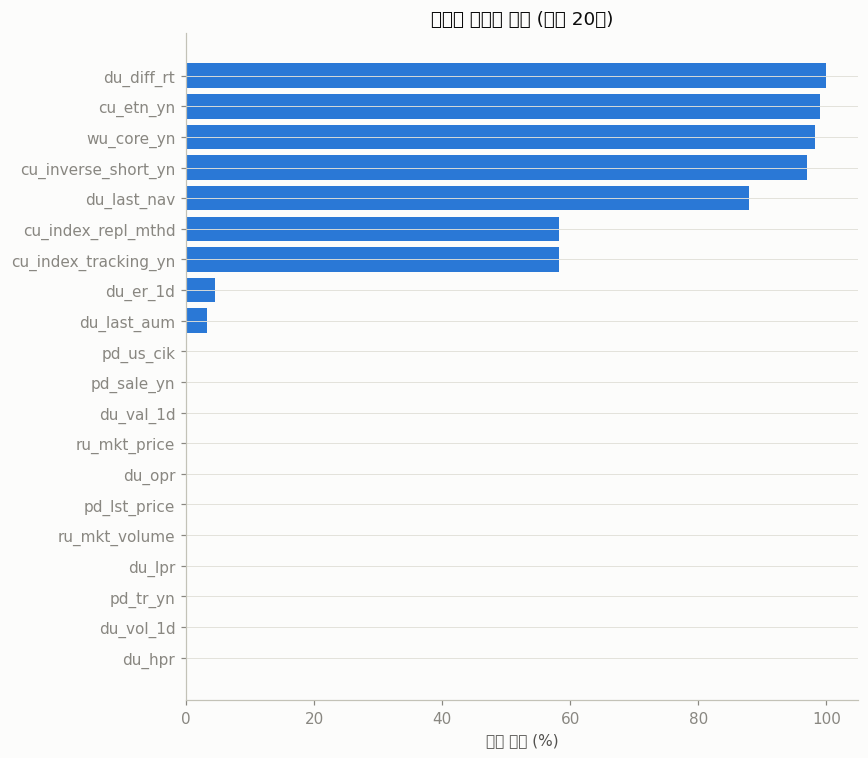

In [10]:
miss_top = missing[missing["missing_count"] > 0].head(20)
if len(miss_top):
    fig, ax = plt.subplots(figsize=(8, max(3, 0.35 * len(miss_top))))
    ax.barh(miss_top.index[::-1], miss_top["missing_pct"][::-1], color=CAT_COLORS[0])
    ax.set_xlabel("결측 비율 (%)")
    ax.set_title("컬럼별 결측치 비율 (상위 20개)")
    plt.tight_layout()
    plt.show()
else:
    print("결측치가 있는 컬럼이 없습니다.")


### 6-1. 글로벌 식별자(ISIN/Lipper ID/US CIK) 완결성 확인

해외 상장 상품은 상장 시장에 따라 이 식별자들이 채워지는 정도가 크게 다를 것으로 예상됩니다
(예: 미국 외 시장에 상장된 상품은 `pd_us_cik`가 대부분 결측일 수 있음). 시장코드(`pd_exg_mkt_cd`)별로 완결성을 교차 확인합니다.


In [11]:
id_complete_cols = [c for c in ["pd_isin_cd", "pd_lipper_id", "pd_us_cik"] if c in df.columns]
if id_complete_cols:
    completeness = df[id_complete_cols].notna().mean().mul(100).round(2).to_frame("완결성(%)")
    display(completeness)

    if "pd_exg_mkt_cd" in df.columns:
        for c in id_complete_cols:
            by_mkt = df.groupby("pd_exg_mkt_cd")[c].apply(lambda s: s.notna().mean() * 100).round(2)
            print(f"\n{c} 시장코드별 완결성(%):")
            display(by_mkt.sort_values(ascending=False).to_frame(c))


,완결성(%)
pd_isin_cd,99.8400
pd_lipper_id,99.8600
pd_us_cik,99.7700



pd_isin_cd 시장코드별 완결성(%):


,pd_isin_cd
pd_exg_mkt_cd,
101,100.0000
102,100.0000
NAS,100.0000
NYS,100.0000
AMX,99.7900



pd_lipper_id 시장코드별 완결성(%):


,pd_lipper_id
pd_exg_mkt_cd,
101,100.0000
102,100.0000
NAS,100.0000
NYS,100.0000
AMX,99.8100



pd_us_cik 시장코드별 완결성(%):


,pd_us_cik
pd_exg_mkt_cd,
101,100.0000
102,100.0000
NYS,100.0000
NAS,99.9200
AMX,99.7200


## 7. 날짜/기준일자 컬럼 처리

스키마상 `du_nav_base_dt`만 timestamp 타입이고 나머지(`cu_upt_dt`, `du_upt_dt`, `wu_upt_dt`, `pd_lstg_dt`, `du_clpr_base_dt`)는
text로 표기되어 있습니다. 국내채권마스터에서 날짜 파싱 함수가 옛 포맷(YYYYMMDD/엑셀 시리얼)만 가정해 실패했던 것을 교훈 삼아,
이번에도 `pd.to_datetime(..., format="mixed")`을 가장 먼저 시도하는 유연한 파서를 사용합니다.


In [12]:
def to_datetime_flexible(s: pd.Series) -> pd.Series:
    '''다양한 날짜 형식(ISO 문자열/YYYYMMDD 정수/엑셀 시리얼 등)을 최대한 파싱.'''
    # 1) 표준 파서로 먼저 시도 (ISO 문자열, 이미 datetime인 경우 등 대부분 커버)
    parsed = pd.to_datetime(s, errors="coerce", format="mixed")
    if parsed.notna().mean() > 0.5:
        return parsed

    # 2) YYYYMMDD 정수/문자열
    s_str = s.astype(str).str.replace(r"\.0$", "", regex=True).str.strip()
    parsed_yyyymmdd = pd.to_datetime(s_str, format="%Y%m%d", errors="coerce")
    if parsed_yyyymmdd.notna().mean() > 0.5:
        return parsed_yyyymmdd

    # 3) 엑셀 시리얼 넘버
    try:
        numeric = pd.to_numeric(s, errors="coerce")
        parsed_serial = pd.to_datetime(numeric, unit="D", origin="1899-12-30", errors="coerce")
        return parsed_serial
    except Exception:
        return parsed


date_parse_summary = []
for col in DATE_COLS:
    parsed = to_datetime_flexible(df[col])
    date_parse_summary.append({
        "column": col,
        "non_null_raw": df[col].notna().sum(),
        "parsed_ok": parsed.notna().sum(),
        "parse_fail_pct": round((1 - parsed.notna().sum() / max(df[col].notna().sum(), 1)) * 100, 2),
        "sample_raw": df[col].dropna().iloc[0] if df[col].notna().any() else None,
    })
    df[f"{col}_parsed"] = parsed

pd.DataFrame(date_parse_summary)


,column,non_null_raw,parsed_ok,parse_fail_pct,sample_raw
0,cu_upt_dt,5646,5646,0.0000,2026-06-14
1,du_upt_dt,5646,5646,0.0000,2026-06-16
2,wu_upt_dt,5646,5646,0.0000,2026-06-14
3,pd_lstg_dt,5638,5638,0.0000,2007-02-23
4,du_clpr_base_dt,5636,5636,0.0000,2026-06-16
5,du_nav_base_dt,5646,5646,0.0000,2026-06-14


## 8. Y/N 플래그 컬럼 분석 (ETN·인버스·지수추종 여부 포함)

이 스키마는 국내ETF마스터에는 없던 `cu_etn_yn`(ETN 여부), `cu_inverse_short_yn`(인버스/공매도 여부),
`cu_index_tracking_yn`(지수추종 여부)을 **명시적으로** 제공합니다. 값 형태가 `Y/N`, `1/0`, `True/False` 등으로
섞여 있을 수 있어 정규화 후 비율을 확인합니다.


In [13]:
def normalize_flag(s: pd.Series) -> pd.Series:
    '''Y/N, 1/0, True/False 등 혼재된 플래그 값을 문자열 Y/N으로 정규화.'''
    mapping = {
        "Y": "Y", "y": "Y", "1": "Y", 1: "Y", 1.0: "Y", True: "Y",
        "N": "N", "n": "N", "0": "N", 0: "N", 0.0: "N", False: "N",
    }
    return s.map(lambda v: mapping.get(v, v))


flag_summary_rows = []
for col in FLAG_COLS:
    normalized = normalize_flag(df[col])
    vc = normalized.fillna("(결측)").astype(str).value_counts()
    flag_summary_rows.append({"column": col, **{str(k): v for k, v in vc.items()}})

flag_summary = pd.DataFrame(flag_summary_rows).set_index("column")
flag_summary


,(결측),Y,N
column,,,
cu_etn_yn,5587,59.0000,NaN
cu_index_tracking_yn,3286,"2,360.0000",NaN
cu_inverse_short_yn,5475,171.0000,NaN
pd_sale_yn,10,"5,636.0000",NaN
pd_tr_yn,10,NaN,"5,636.0000"
wu_core_yn,5543,NaN,103.0000
du_base_dt_match_yn,10,NaN,"5,636.0000"


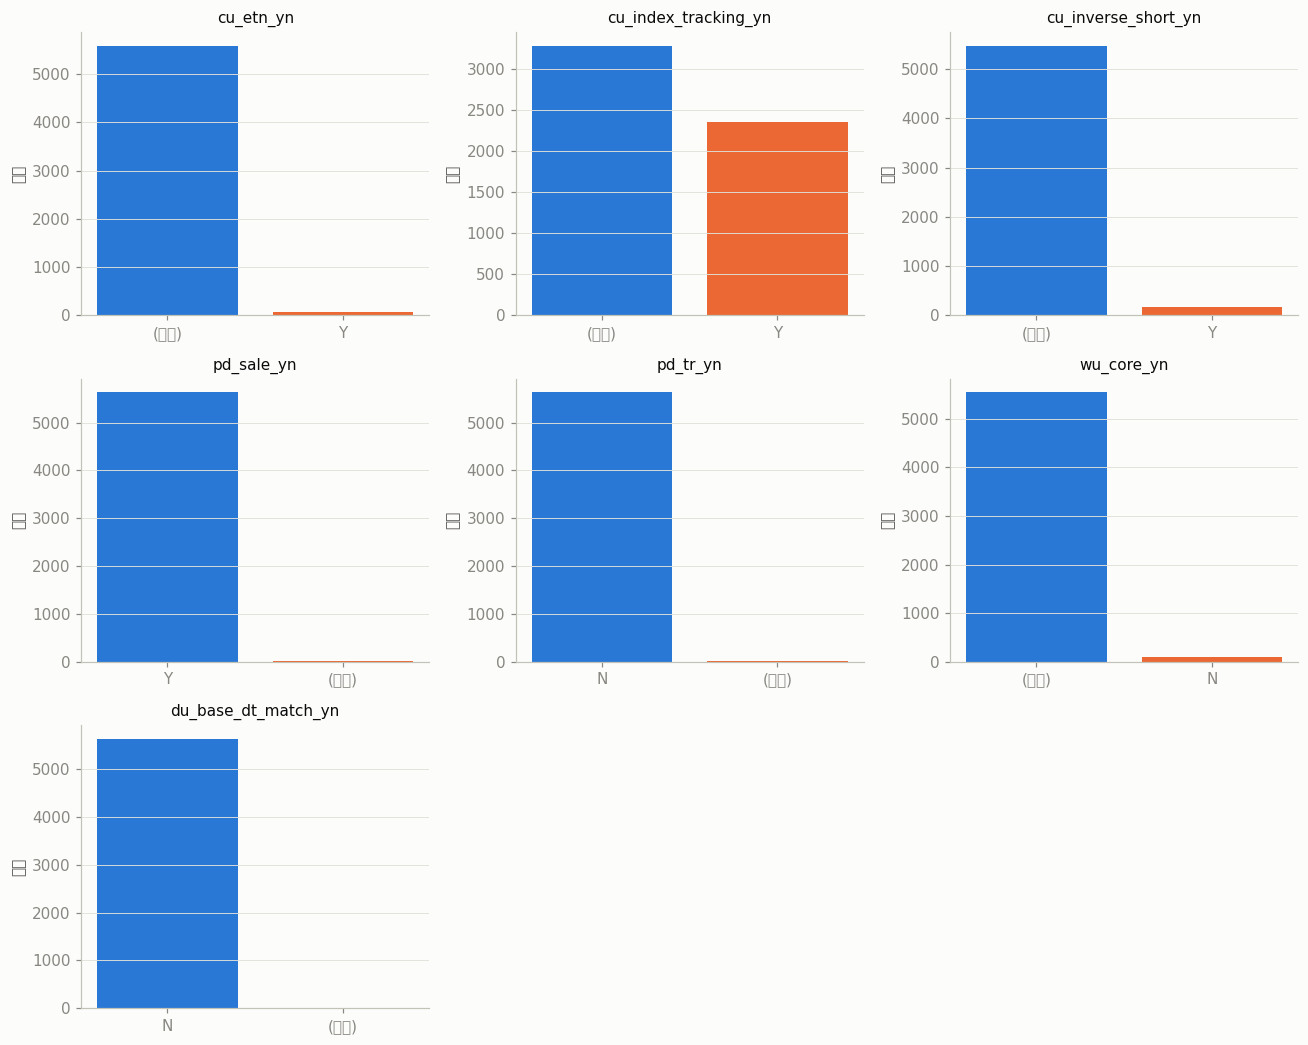

In [14]:
if FLAG_COLS:
    n_cols = 3
    n_rows = int(np.ceil(len(FLAG_COLS) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3.2 * n_rows))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, FLAG_COLS):
        vc = normalize_flag(df[col]).fillna("(결측)").astype(str).value_counts()
        ax.bar([str(x) for x in vc.index], vc.values, color=cat_colors(len(vc)))
        ax.set_title(col, fontsize=10)
        ax.set_ylabel("건수")
    for ax in axes[len(FLAG_COLS):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


### 8-1. 상품속성 플래그 간 정합성 체크

`cu_lev_fector`(레버리지 배수)가 1이 아닌데 `cu_inverse_short_yn`이 N으로 표기되는 등 플래그 간 모순이 있는지 확인합니다.


In [15]:
if {"cu_lev_fector", "cu_inverse_short_yn"}.issubset(df.columns):
    lev_numeric = pd.to_numeric(df["cu_lev_fector"], errors="coerce")
    inv_flag = normalize_flag(df["cu_inverse_short_yn"])
    mismatch = df[(lev_numeric.notna()) & (lev_numeric != 1) & (inv_flag == "N")]
    print(f"레버리지/인버스 배수(≠1)인데 cu_inverse_short_yn=N인 행: {len(mismatch):,}건")
    if len(mismatch):
        display(mismatch[["pd_itm_no", "cu_lev_fector", "cu_inverse_short_yn"]].head(10))

if {"cu_etn_yn", "pd_grp_no"}.issubset(df.columns):
    display(pd.crosstab(normalize_flag(df["cu_etn_yn"]).fillna("(결측)"), df["pd_grp_no"].fillna("(결측)")))


pd_grp_no,ETF,ETN
cu_etn_yn,,
(결측),5587,0
Y,0,59


## 9. 통화 불일치 확인 (pd_curr_cd vs pd_trd_ccy)

해외 상장 ETF는 상품의 기준통화(`pd_curr_cd`)와 실제 거래소 거래통화(`pd_trd_ccy`)가 다를 수 있습니다
(예: 유럽에 상장된 미국 지수 추종 ETF가 EUR로 거래되는 경우). 국내ETF마스터에는 없던 개념이라 별도로 확인합니다.


In [16]:
if {"pd_curr_cd", "pd_trd_ccy"}.issubset(df.columns):
    same = (df["pd_curr_cd"] == df["pd_trd_ccy"])
    print(f"기준통화 == 거래통화: {same.sum():,}건 ({same.mean()*100:.2f}%)")
    print(f"기준통화 != 거래통화: {(~same).sum():,}건 ({(~same).mean()*100:.2f}%)")
    display(pd.crosstab(df["pd_curr_cd"], df["pd_trd_ccy"], margins=True))


기준통화 == 거래통화: 5,637건 (99.84%)
기준통화 != 거래통화: 9건 (0.16%)


pd_trd_ccy,USD,All
pd_curr_cd,,
INR,1,1
USD,5637,5637
All,5638,5638


## 10. 범주형 변수 EDA

In [17]:
for col in CATEGORY_COLS:
    vc = df[col].value_counts(dropna=False)
    print(f"\n### {col} (고유값 {df[col].nunique(dropna=False)}개)")
    display(vc.head(10).to_frame("count").assign(pct=lambda x: (x["count"] / len(df) * 100).round(2)))



### pd_exg_mkt_cd (고유값 5개)


,count,pct
pd_exg_mkt_cd,,
AMX,4241,75.1200
NAS,1296,22.9500
NYS,78,1.3800
102,22,0.3900
101,9,0.1600



### pd_mkt_id (고유값 1개)


,count,pct
pd_mkt_id,,
US,5646,100.0000



### pd_curr_cd (고유값 3개)


,count,pct
pd_curr_cd,,
USD,5637,99.8400
NaN,8,0.1400
INR,1,0.0200


... (14 outputs left out)


### du_clpr_src (고유값 2개)


,count,pct
du_clpr_src,,
pd65n101.tday_clpr,5636,99.8200
NaN,10,0.1800



### cu_base_index (고유값 1734개)


,count,pct
cu_base_index,,
Index is not provided by Management Company,1984,35.1400
Index is not available on Lipper Database,721,12.7700
S&P 500 TR,335,5.9300
Bloomberg U.S. Aggregate Bond TR,89,1.5800
S&P 500 CR,51,0.9000
Russell 1000 Growth TR,35,0.6200
Russell 1000 Value TR,34,0.6000
MSCI EAFE NR USD,28,0.5000
Russell 3000 TR,27,0.4800


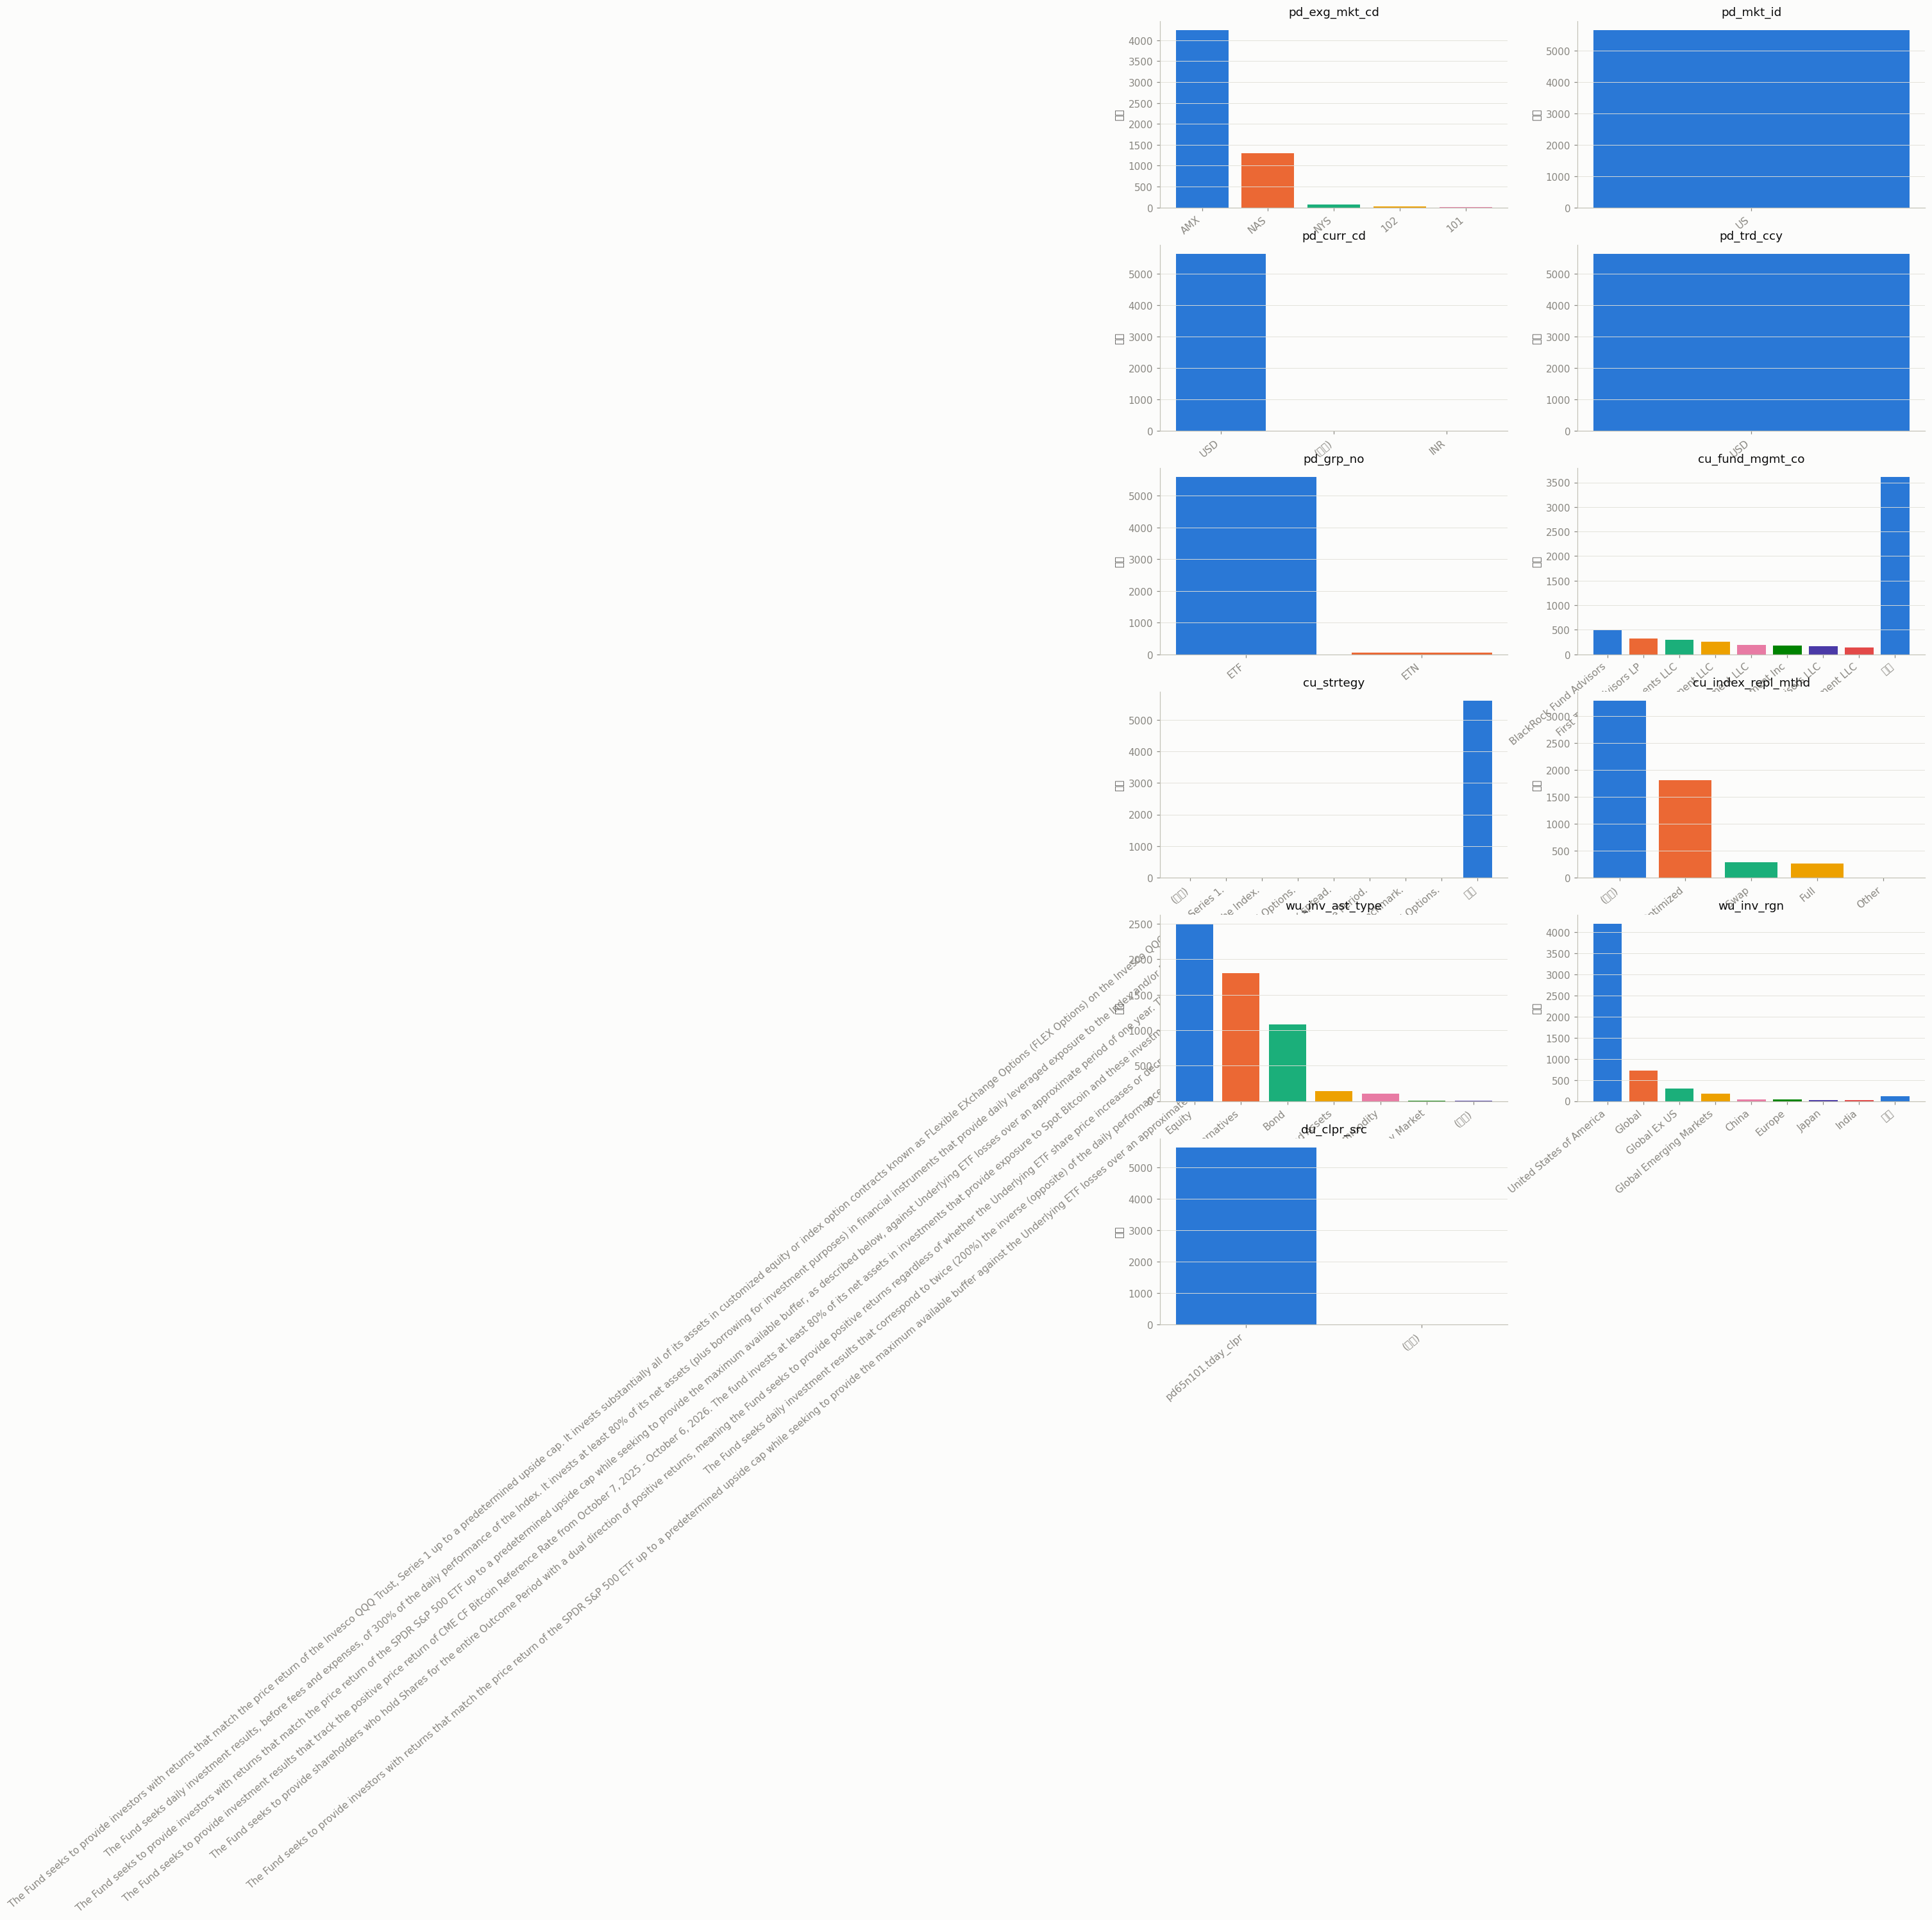

In [18]:
def plot_top_categories(col, top_n=8, ax=None):
    vc = df[col].fillna("(결측)").astype(str).value_counts()
    top = vc.head(top_n)
    if len(vc) > top_n:
        other = pd.Series({"기타": vc.iloc[top_n:].sum()})
        top = pd.concat([top, other])

    own_ax = ax is None
    if own_ax:
        fig, ax = plt.subplots(figsize=(7, 4))
    colors = cat_colors(len(top))
    ax.bar([str(x) for x in top.index], top.values, color=colors)
    ax.set_title(col)
    ax.set_ylabel("건수")
    ax.tick_params(axis="x", rotation=40)
    for label in ax.get_xticklabels():
        label.set_ha("right")
    if own_ax:
        plt.tight_layout()
        plt.show()


plot_cols = [c for c in CATEGORY_COLS if c != "cu_base_index"]  # 지수명은 카디널리티가 너무 높아 제외
n_cols = 2
n_rows = int(np.ceil(len(plot_cols) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(7 * n_cols, 4 * n_rows))
axes = np.array(axes).reshape(-1)
for ax, col in zip(axes, plot_cols):
    plot_top_categories(col, ax=ax)
for ax in axes[len(plot_cols):]:
    ax.axis("off")
plt.tight_layout()
plt.show()


## 11. 수치형 변수 기술통계

In [19]:
stats = df[NUMERIC_COLS].describe().T
stats["skew"] = df[NUMERIC_COLS].skew()
stats["kurtosis"] = df[NUMERIC_COLS].kurtosis()
stats.sort_values("skew", ascending=False)


,count,mean,std,min,25%,50%,75%,max,skew,kurtosis
pd_lst_price,"5,636.0000",0.0000,0.0001,0.0000,0.0000,0.0000,0.0000,0.0100,75.0733,"5,636.0000"
du_bpr,"5,636.0000",68.7423,"1,577.1107",0.3089,24.8686,33.5029,51.1169,"118,350.0000",74.8909,"5,617.6121"
du_lpr,"5,636.0000",69.4003,"1,593.8149",0.2842,24.9700,33.6155,51.1937,"119,600.0000",74.8845,"5,616.9624"
du_clpr,"5,636.0000",69.9490,"1,611.8099",0.2842,25.0200,33.8040,51.3643,"120,950.0000",74.8843,"5,616.9422"
du_opr,"5,636.0000",69.7049,"1,594.4884",0.3747,25.0300,33.7647,51.3800,"119,650.0000",74.8830,"5,616.8094"
ru_mkt_price,"5,636.0000",69.8211,"1,603.8248",0.2842,25.0046,33.7645,51.3643,"120,350.0000",74.8824,"5,616.7522"
du_hpr,"5,636.0000",70.1410,"1,603.8352",0.3901,25.0800,33.9198,51.5539,"120,350.0000",74.8804,"5,616.5464"
du_val_1d,"5,636.0000","44,528,960.0531","561,319,451.8987",0.0000,"59,411.7500","467,419.5000","4,332,556.2500","34,411,870,125.0000",44.8184,"2,555.7616"
du_vol_1d,"5,636.0000","796,439.3392","8,297,499.5496",0.0000,"1,933.7500","13,239.0000","103,432.5000","457,196,285.0000",37.6184,"1,811.8365"
ru_mkt_volume,"5,636.0000","796,439.3392","8,297,499.5496",0.0000,"1,933.7500","13,239.0000","103,432.5000","457,196,285.0000",37.6184,"1,811.8365"


## 12. 수치형 변수 분포 시각화

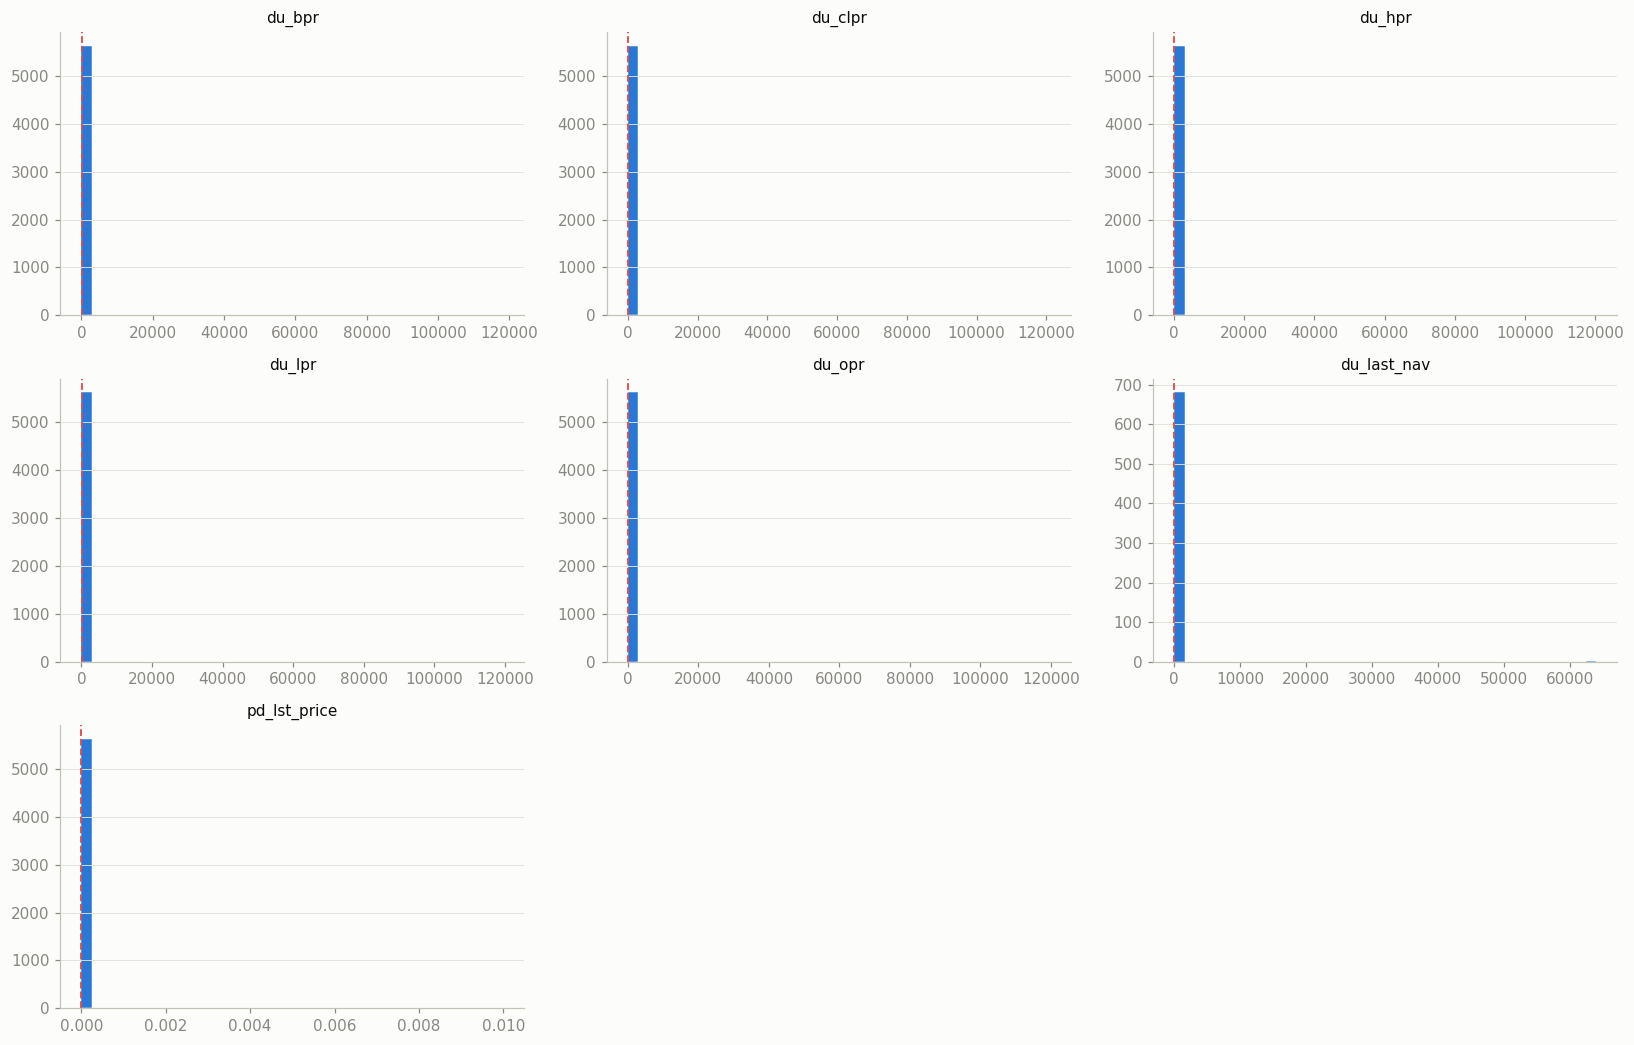

In [20]:
def plot_histograms(cols, n_cols=3, bins=40):
    cols = [c for c in cols if c in df.columns]
    if not cols:
        print("표시할 컬럼이 없습니다.")
        return
    n_rows = int(np.ceil(len(cols) / n_cols))
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 3.2 * n_rows))
    axes = np.array(axes).reshape(-1)
    for ax, col in zip(axes, cols):
        data = pd.to_numeric(df[col], errors="coerce").dropna()
        ax.hist(data, bins=bins, color=CAT_COLORS[0], edgecolor="white", linewidth=0.3)
        ax.set_title(col, fontsize=10)
        if len(data):
            ax.axvline(data.median(), color=CAT_COLORS[7], linewidth=1.2, linestyle="--", label="median")
    for ax in axes[len(cols):]:
        ax.axis("off")
    plt.tight_layout()
    plt.show()


plot_histograms(PRICE_COLS)


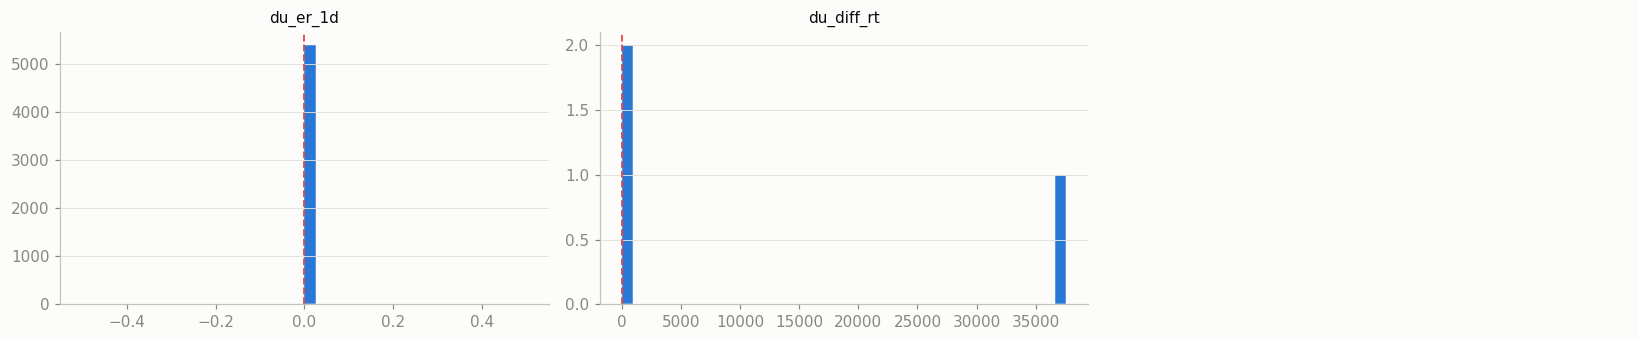

In [21]:
plot_histograms(RETURN_COLS + LEVERAGE_COLS)


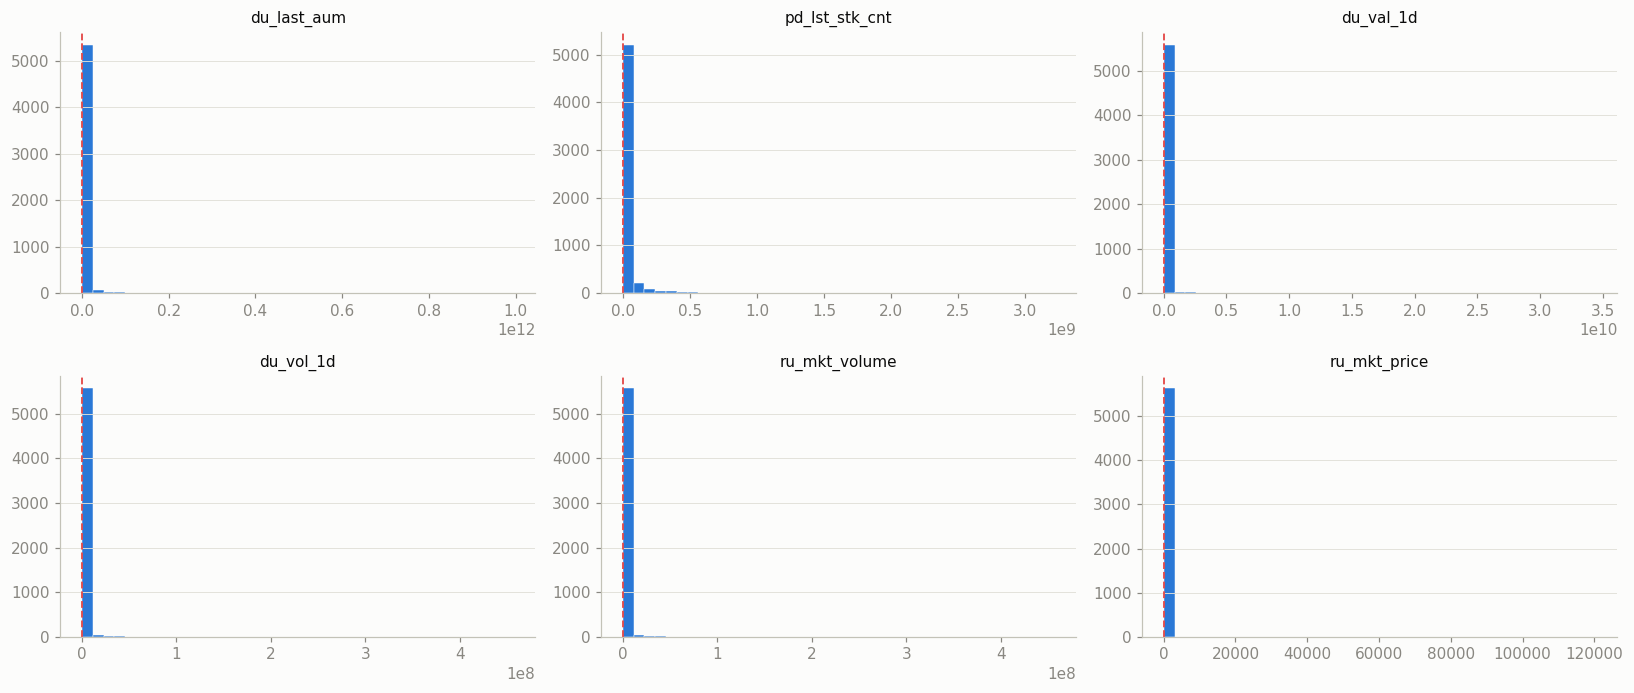

In [22]:
plot_histograms(SIZE_COLS + VOLUME_COLS)


## 13. 이상치 탐지 (IQR 기준)

In [23]:
def iqr_outlier_summary(cols):
    rows = []
    for col in cols:
        s = pd.to_numeric(df[col], errors="coerce").dropna()
        if s.empty:
            continue
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_out = ((s < lo) | (s > hi)).sum()
        rows.append({
            "column": col, "q1": q1, "q3": q3, "iqr": iqr,
            "lower": lo, "upper": hi,
            "n_outliers": n_out, "pct_outliers": round(n_out / len(s) * 100, 2),
        })
    return pd.DataFrame(rows).sort_values("pct_outliers", ascending=False)


outlier_summary = iqr_outlier_summary(NUMERIC_COLS)
outlier_summary


,column,q1,q3,iqr,lower,upper,n_outliers,pct_outliers
9,du_val_1d,"59,411.7500","4,332,556.2500","4,273,144.5000","-6,350,305.0000","10,742,273.0000",963,17.0900
10,du_vol_1d,"1,933.7500","103,432.5000","101,498.7500","-150,314.3750","255,680.6250",949,16.8400
11,ru_mkt_volume,"1,933.7500","103,432.5000","101,498.7500","-150,314.3750","255,680.6250",949,16.8400
13,du_last_aum,"15,905,000.0000","535,570,000.0000","519,665,000.0000","-763,592,500.0000","1,315,067,500.0000",856,15.6800
14,pd_lst_stk_cnt,"500,001.0000","12,050,002.0000","11,550,001.0000","-16,825,000.5000","29,375,003.5000",841,14.9000
2,du_hpr,25.0800,51.5539,26.4739,-14.6308,91.2647,554,9.8300
4,du_opr,25.0300,51.3800,26.3500,-14.4950,90.9050,554,9.8300
1,du_clpr,25.0200,51.3643,26.3443,-14.4966,90.8808,549,9.7400
12,ru_mkt_price,25.0046,51.3643,26.3597,-14.5349,90.9039,548,9.7200
3,du_lpr,24.9700,51.1937,26.2237,-14.3656,90.5294,545,9.6700


## 14. 레버리지/인버스 상품 특성

`cu_lev_fector`(레버리지 배수)가 1이 아닌 상품군에서 수익률/괴리율 이상치가 늘어나는 것은
데이터 오류가 아니라 상품 특성일 가능성이 높습니다(국내ETF마스터와 동일한 관점). `cu_inverse_short_yn`과 교차해서 확인합니다.


In [24]:
if "cu_lev_fector" in df.columns:
    lev_numeric = pd.to_numeric(df["cu_lev_fector"], errors="coerce")
    print(lev_numeric.value_counts(dropna=False).sort_index())

    if "du_diff_rt" in df.columns:
        is_leveraged = lev_numeric.notna() & (lev_numeric != 1)
        for label, mask in [("일반(1배)", ~is_leveraged), ("레버리지/인버스(≠1배)", is_leveraged)]:
            s = pd.to_numeric(df.loc[mask, "du_diff_rt"], errors="coerce").dropna()
            if len(s):
                print(f"{label}: n={len(s):,}, du_diff_rt 표준편차={s.std():.4f}, 절대값 90분위={s.abs().quantile(0.9):.4f}")


## 15. 수치형 변수 전체 상관관계

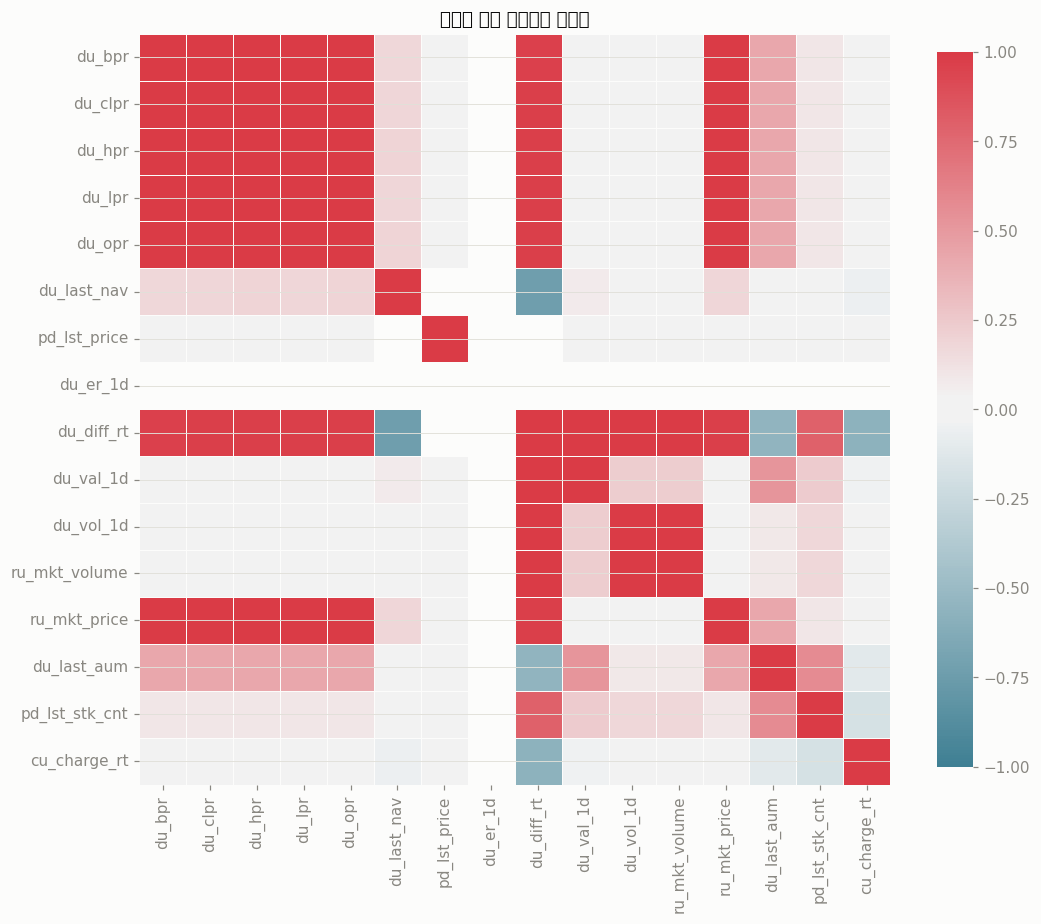

In [25]:
corr = df[NUMERIC_COLS].apply(pd.to_numeric, errors="coerce").corr()
fig, ax = plt.subplots(figsize=(0.5 * len(NUMERIC_COLS) + 2, 0.5 * len(NUMERIC_COLS) + 2))
sns.heatmap(
    corr, cmap=DIVERGING_CMAP, center=0, vmin=-1, vmax=1,
    square=True, linewidths=0.4, linecolor=SURFACE, cbar_kws={"shrink": 0.7}, ax=ax,
)
ax.set_title("수치형 변수 상관관계 히트맵")
plt.tight_layout()
plt.show()


In [26]:
corr_pairs = (
    corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
    .stack()
    .rename("corr")
    .to_frame()
    .assign(abs_corr=lambda x: x["corr"].abs())
    .sort_values("abs_corr", ascending=False)
)
corr_pairs.head(20)


,,corr,abs_corr
du_vol_1d,ru_mkt_volume,1.0000,1.0000
du_clpr,ru_mkt_price,1.0000,1.0000
du_hpr,ru_mkt_price,1.0000,1.0000
du_lpr,du_opr,1.0000,1.0000
du_clpr,du_hpr,1.0000,1.0000
du_opr,ru_mkt_price,1.0000,1.0000
du_clpr,du_opr,1.0000,1.0000
du_hpr,du_opr,1.0000,1.0000
du_clpr,du_lpr,1.0000,1.0000
du_lpr,ru_mkt_price,1.0000,1.0000


## 16. 투자지역(wu_inv_rgn) × 자산유형(wu_inv_ast_type) 교차분석

In [27]:
if {"wu_inv_rgn", "wu_inv_ast_type"}.issubset(df.columns):
    display(pd.crosstab(df["wu_inv_rgn"].fillna("(결측)"), df["wu_inv_ast_type"].fillna("(결측)"), margins=True))


wu_inv_ast_type,(결측),Alternatives,Bond,Commodity,Equity,Mixed Assets,Money Market,All
wu_inv_rgn,,,,,,,,
(결측),8,0,0,0,0,0,0,8
ASEAN,0,0,0,0,1,0,0,1
Africa,0,0,0,0,1,0,0,1
Argentina,0,0,0,0,1,0,0,1
Asia Pacific,0,0,1,0,6,0,0,7
...,...,...,...,...,...,...,...,...
United Arab Emirates,0,0,0,0,1,0,0,1
United Kingdom,0,1,0,0,4,0,0,5
United States of America,0,1575,972,79,1482,79,9,4196


## 17. 운용사(cu_fund_mgmt_co)별 AUM 요약

In [28]:
if {"cu_fund_mgmt_co", "du_last_aum"}.issubset(df.columns):
    aum_numeric = pd.to_numeric(df["du_last_aum"], errors="coerce")
    by_mgmt = (
        df.assign(_aum=aum_numeric)
        .groupby("cu_fund_mgmt_co")["_aum"]
        .agg(["count", "sum", "mean"])
        .sort_values("sum", ascending=False)
        .head(15)
    )
    display(by_mgmt)


,count,sum,mean
cu_fund_mgmt_co,,,
BlackRock Fund Advisors,487,"4,286,190,400,000.0000","8,801,212,320.3285"
"Vanguard Capital Management, LLC",62,"2,999,597,890,000.0000","48,380,611,129.0323"
Vanguard Portfolio Management LLC,45,"1,407,368,750,000.0000","31,274,861,111.1111"
SSGA Funds Management Inc,173,"1,044,911,970,000.0000","6,039,953,583.8150"
Invesco Capital Management LLC,245,"956,729,980,000.0000","3,905,020,326.5306"
State Street Global Advisors Trust Co,1,"783,071,880,000.0000","783,071,880,000.0000"
Charles Schwab Investment Management Inc,34,"580,123,380,000.0000","17,062,452,352.9412"
JP Morgan Investment Management Inc,77,"312,193,010,000.0000","4,054,454,675.3247"
Dimensional Fund Advisors LP,40,"276,581,000,000.0000","6,914,525,000.0000"


## 18. 갱신주기(접두사)별 결측률 비교

국내ETF마스터와 동일한 접두사 체계(`pd_`/`cu_`/`du_`/`wu_`/`ru_`)를 사용하므로 같은 방식으로 비교합니다.
이 스키마엔 `nru_`(준실시간) 접두사가 없습니다.


In [29]:
prefix_groups = {}
for col in df.columns:
    for p in ["pd_", "cu_", "du_", "wu_", "ru_"]:
        if col.startswith(p):
            prefix_groups.setdefault(p, []).append(col)
            break

prefix_missing = {
    p: df[cols].isna().mean().mean() * 100
    for p, cols in prefix_groups.items()
}
pd.Series(prefix_missing).sort_values(ascending=False).round(2).to_frame("평균 결측률(%)")


,평균 결측률(%)
cu_,31.2800
wu_,19.6900
du_,10.4100
ru_,0.1800
pd_,0.0800


## 19. 중복/파생 필드 의심 컬럼

상관계수가 1.00에 가까운 페어는 중복 또는 파생 필드일 가능성이 높습니다(다른 세 데이터셋에서 반복 확인된 패턴).


In [30]:
near_duplicate = corr_pairs[corr_pairs["abs_corr"] >= 0.99]
near_duplicate


,,corr,abs_corr
du_vol_1d,ru_mkt_volume,1.0000,1.0000
du_clpr,ru_mkt_price,1.0000,1.0000
du_hpr,ru_mkt_price,1.0000,1.0000
du_lpr,du_opr,1.0000,1.0000
du_clpr,du_hpr,1.0000,1.0000
du_opr,ru_mkt_price,1.0000,1.0000
du_clpr,du_opr,1.0000,1.0000
du_hpr,du_opr,1.0000,1.0000
du_clpr,du_lpr,1.0000,1.0000
du_lpr,ru_mkt_price,1.0000,1.0000
